<center><font size="6.5"> Brain Cancer Classification Using Deep Learning </center>


<center><p float="center">
  <img src="https://user18239.na.imgto.link/public/20261022/b60ed15fa50b44d796c49e15-brain-cancer-classification-infographic.avif" width="720"/>
</p></center>

## Objective

The objective of this project is to develop a deep learning model that analyzes brain MRI images and classifies them into three categories: Glioma, Meningioma, and Brain Tumor, based on the dataset labels. The project compares CNN and CNN + LSTM architectures to evaluate their classification performance and generalization.

## Dataset description
- Total images: 600 MRI images
- Image size: \(224 \times 224\) pixels
- Image channels: 3 (RGB)
- Number of classes: 3

The dataset provides MRI images used to train and evaluate the deep learning models. Each image must have the correct corresponding class label for the model to learn meaningful patterns.

## Import the Necessary Libraries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import cv2

from tensorflow.keras.models import Sequential
from tensorflow import keras
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image

In [ ]:
import tensorflow as tf
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


## Loading the data

In [ ]:

from google.colab import drive

drive.mount('/content/drive')

images = np.load(
    '/content/drive/MyDrive/GenAIdataset/Dataset/brain_images.npy'
)

label = pd.read_csv(
    '/content/drive/MyDrive/GenAIdataset/Dataset/class_names.csv'
)

print("Images shape:", images.shape)
print("Label data:")
print(label)


Mounted at /content/drive
Images shape: (600, 224, 224, 3)
Label data:
     Class_Name
0  brain_glioma
1   brain_menin
2   brain_tumor


## Data Overview

In [ ]:
print(images.shape)

(600, 224, 224, 3)


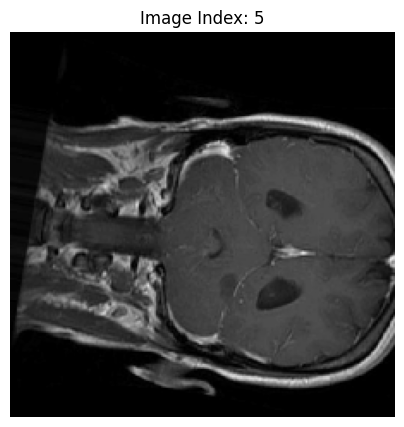

In [ ]:

img = images[5]

plt.figure(figsize=(5, 5))

if img.max() <= 1:
    plt.imshow(img)
else:
    plt.imshow(img.astype("uint8"))

plt.title("Image Index: 5")
plt.axis("off")
plt.show()


## Exploratory Data Analysis (EDA)


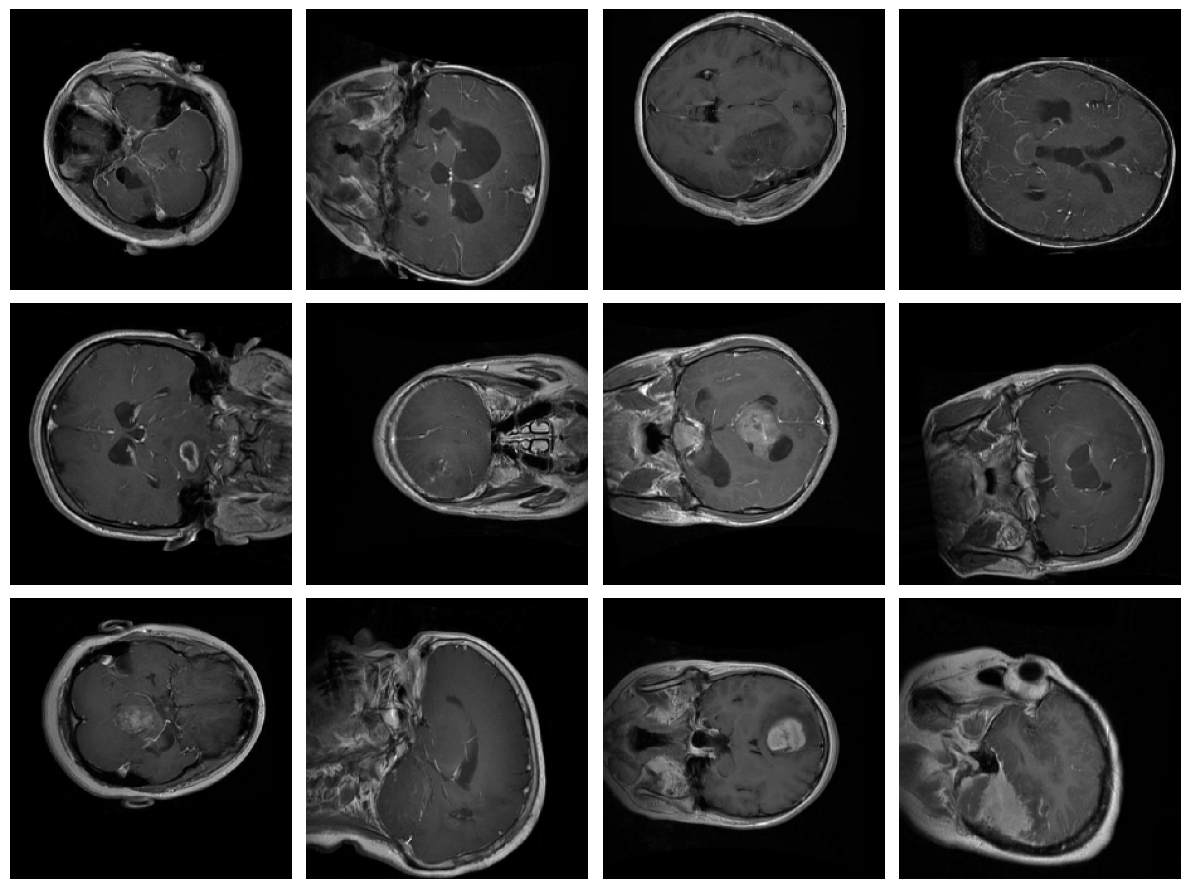

In [ ]:
plt.figure(figsize=(12,9))
for i in range(12):
  idx = i * 20
  plt.subplot(3,4,i+1)
  plt.imshow(images[idx])
  # Since label only has 3 unique class names, we display the image index instead of an out-of-bounds lookup

  plt.axis('off')
plt.tight_layout()
plt.show()

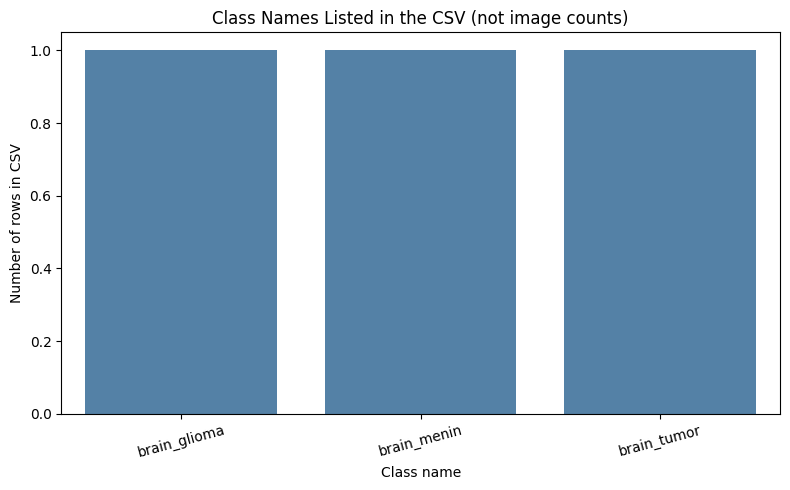

In [ ]:
# This CSV lists class names; it does not contain one row per image.
# Therefore, this plot shows the class names listed in the CSV, NOT image counts.
plt.figure(figsize=(8, 5))
sns.countplot(x='Class_Name', data=label, color='steelblue')
plt.title('Class Names Listed in the CSV (not image counts)')
plt.xlabel('Class name')
plt.ylabel('Number of rows in CSV')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [ ]:

print("Class names in CSV:")
print(label)

print("\nNumber of images:", len(images))
print("Number of class names:", len(label))


Class names in CSV:
     Class_Name
0  brain_glioma
1   brain_menin
2   brain_tumor

Number of images: 600
Number of class names: 3


## Data preprocessing

Label encoding

The three categories are represented by integer labels:
- 0 — Glioma
- 1 — Meningioma
- 2 — Brain Tumor
These mappings must match the actual labels assigned to the images.

In [ ]:
# Keep the CSV class names as text. This mapping is for reference only;
# it does not automatically assign a label to every image.
class_to_id = {
    'brain_glioma': 0,
    'brain_menin': 1,
    'brain_tumor': 2
}

print("Class-to-label mapping:")
print(class_to_id)
print("Class names in CSV:", label['Class_Name'].tolist())


Class-to-label mapping:
{'brain_glioma': 0, 'brain_menin': 1, 'brain_tumor': 2}
Class names in CSV: ['brain_glioma', 'brain_menin', 'brain_tumor']


In [ ]:

print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())
print("Data type:", images.dtype)

print("Completely black images:",
      np.sum(np.max(images, axis=(1, 2, 3)) == 0))


Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float32
Completely black images: 0


In [ ]:
class_names = ['brain_glioma', 'brain_menin', 'brain_tumor']

# IMPORTANT: This creates labels based on an assumption that images are stored
# in this exact order: 200 glioma images, then 200 meningioma images,
# then 200 brain_tumor images. Use this ONLY if you verified the saved image order.
# If images were mixed or loaded from folders in another order, create targets
# from the original per-image labels instead. Incorrect labels invalidate results.
images_are_grouped_by_class_in_this_order = True  # Set True only after verification

if not images_are_grouped_by_class_in_this_order:
    raise ValueError(
        "Create targets from the verified label for each image. Do not assume image order."
    )

if len(images) != 600:
    raise ValueError(f"Expected 600 images based on this label setup; found {len(images)}.")

targets = np.repeat([0, 1, 2], 200)

assert len(images) == len(targets), "Each image must have exactly one label."
print("Total images:", len(images))
print("Total labels:", len(targets))
print("Label counts:", dict(zip(class_names, np.bincount(targets))))


Total images: 600
Total labels: 600
Label counts: {'brain_glioma': np.int64(200), 'brain_menin': np.int64(200), 'brain_tumor': np.int64(200)}


## Train, Validation, and Test Split

The intended split is 70:15:15. Stratification preserves the proportions of the supplied labels, but it cannot correct wrong labels. If several images belong to the same patient, use a patient-level split to reduce data leakage.


In [ ]:

from sklearn.model_selection import train_test_split

# Split 70% for training and 30% for temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    images,
    targets,
    test_size=0.30,
    random_state=42,
    stratify=targets
)

# Split temporary data equally into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)


Training images: (420, 224, 224, 3)
Validation images: (90, 224, 224, 3)
Testing images: (90, 224, 224, 3)

Training labels: (420,)
Validation labels: (90,)
Testing labels: (90,)


## Pixel Values and Normalization

Check the pixel range first. The saved notebook output showed values between 0 and 1, so do not divide by 255 again if that is still true. Converting to `float32` changes the data type, not the pixel scale.


In [ ]:

# Convert images to float32
X_train_normalized = X_train.astype("float32")
X_val_normalized = X_val.astype("float32")
X_test_normalized = X_test.astype("float32")

print("Training pixel range:",
      X_train_normalized.min(),
      X_train_normalized.max())

print("Validation pixel range:",
      X_val_normalized.min(),
      X_val_normalized.max())

print("Testing pixel range:",
      X_test_normalized.min(),
      X_test_normalized.max())


Training pixel range: 0.0 1.0
Validation pixel range: 0.0 1.0
Testing pixel range: 0.0 1.0


## Model Evaluation

In [ ]:
evaluation_result = pd.DataFrame(columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])

## CNN model 1

Architecture: Three convolutional and pooling blocks, followed by dense layers and a softmax output.

The first CNN model extracts features from MRI images using multiple convolutional layers. The deeper layers learn increasingly complex image patterns that may help distinguish the classes.

                 BRAIN MRI IMAGE
                 (224 × 224 × 3)
                        |
                        v
          +---------------------------+
          |       CNN LAYERS          |
          |                           |
          | Conv2D (32 filters)       |
          | MaxPooling2D (2 × 2)      |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |       CNN LAYERS          |
          |                           |
          | Conv2D (64 filters)       |
          | MaxPooling2D (2 × 2)      |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |       CNN LAYERS          |
          |                           |
          | Conv2D (128 filters)      |
          | MaxPooling2D (2 × 2)      |
          +---------------------------+
                        |
                        v
                 CNN FEATURE MAP
                 (28 × 28 × 128)
                        |
                        v
          +---------------------------+
          |          FLATTEN          |
          |   Convert to 1D Vector    |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |       DENSE LAYER         |
          |        128 Units          |
          |      ReLU Activation      |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |         DROPOUT           |
          |           0.5             |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |      SOFTMAX OUTPUT       |
          |         3 Classes         |
          +---------------------------+
                        |
              +---------+---------+
              |         |         |
              v         v         v
           GLIOMA   MENINGIOMA  BRAIN TUMOR
             (0)        (1)        (2)

In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

model_cnn1 = Sequential([
    Input(shape=(224, 224, 3)),

    # Convolution layer 1
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Convolution layer 2
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Convolution layer 3
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Classification layers
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Three output classes
    Dense(3, activation='softmax')
])

model_cnn1.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn1.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,819 (49.36 MB)

 Trainable params: 12,938,819 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_cnn1 = EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history = model_cnn1.fit(
    X_train_normalized,
    y_train,
    validation_data=(X_val_normalized, y_val),
    epochs=20,
    batch_size=16,
    callbacks=[early_stop_cnn1],
    verbose=1
)


Epoch 1/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 18s 343ms/step - accuracy: 0.5048 - loss: 0.8797 - val_accuracy: 0.5333 - val_loss: 0.8478
Epoch 2/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.5929 - loss: 0.7781 - val_accuracy: 0.5778 - val_loss: 0.8067
Epoch 3/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.6500 - loss: 0.6857 - val_accuracy: 0.6000 - val_loss: 0.8184
Epoch 4/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.6810 - loss: 0.6356 - val_accuracy: 0.6222 - val_loss: 0.7653
Epoch 5/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.7286 - loss: 0.5970 - val_accuracy: 0.6778 - val_loss: 0.7508
Epoch 6/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.7738 - loss: 0.5070 - val_accuracy: 0.6222 - val_loss: 0.7535
Epoch 7/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.8429 - loss: 0.4537 - val_accuracy: 0.6778 - val_loss: 0.7033
Epoch 8/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8405 - loss: 0.3813 - val_accuracy: 0.6000 -


=============== Training Report ===============
Loss: 0.1085
Accuracy: 0.9929
              precision    recall  f1-score   support

brain_glioma       0.99      0.99      0.99       140
 brain_menin       0.99      0.99      0.99       140
 brain_tumor       1.00      1.00      1.00       140

    accuracy                           0.99       420
   macro avg       0.99      0.99      0.99       420
weighted avg       0.99      0.99      0.99       420



/tmp/ipykernel_1448/1000830944.py:71: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_result = pd.concat(



=============== Validation Report ===============
Loss: 0.6713
Accuracy: 0.7222
              precision    recall  f1-score   support

brain_glioma       0.69      0.67      0.68        30
 brain_menin       0.62      0.67      0.65        30
 brain_tumor       0.86      0.83      0.85        30

    accuracy                           0.72        90
   macro avg       0.73      0.72      0.72        90
weighted avg       0.73      0.72      0.72        90


=============== Testing Report ===============
Loss: 0.7441
Accuracy: 0.7556
              precision    recall  f1-score   support

brain_glioma       0.80      0.80      0.80        30
 brain_menin       0.73      0.53      0.62        30
 brain_tumor       0.74      0.93      0.82        30

    accuracy                           0.76        90
   macro avg       0.75      0.76      0.75        90
weighted avg       0.75      0.76      0.75        90



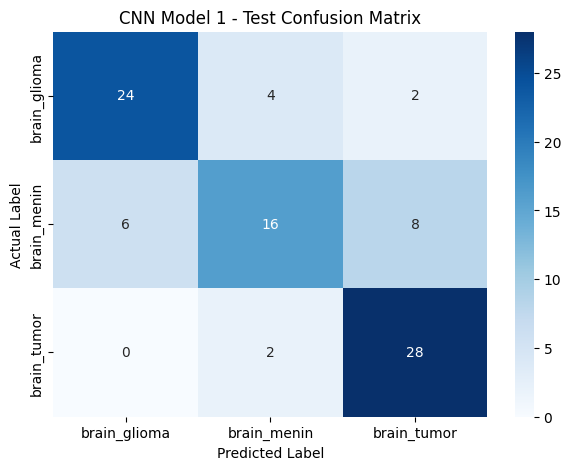


Evaluation Results Summary:


,Model,Accuracy,Precision,Recall,F1-Score,Dataset
0,CNN Model 1 (3 Conv Layers),0.9929,0.9929,0.9929,0.9929,Training
1,CNN Model 1 (3 Conv Layers),0.7222,0.7256,0.7222,0.7235,Validation
2,CNN Model 1 (3 Conv Layers),0.7556,0.7547,0.7556,0.7463,Testing


In [ ]:

from sklearn.metrics import (
    classification_report,
    precision_recall_fscore_support,
    confusion_matrix,
    accuracy_score
)
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

class_names = [
    'brain_glioma',
    'brain_menin',
    'brain_tumor'
]

# Create evaluation results table if it does not exist
if 'evaluation_result' not in globals():
    evaluation_result = pd.DataFrame(
        columns=['Model', 'Dataset', 'Accuracy',
                 'Precision', 'Recall', 'F1-Score']
    )

# Evaluate on training, validation and test datasets
datasets = {
    'Training': (X_train_normalized, y_train),
    'Validation': (X_val_normalized, y_val),
    'Testing': (X_test_normalized, y_test)
}

for dataset_name, (X, y_true) in datasets.items():

    # Calculate loss and accuracy
    loss, accuracy = model_cnn1.evaluate(X, y_true, verbose=0)

    # Predict classes
    y_prob = model_cnn1.predict(X, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate precision, recall and F1-score
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average='macro',
        zero_division=0
    )

    print(f"\n{'=' * 15} {dataset_name} Report {'=' * 15}")
    print(f"Loss: {loss:.4f}")
    print(f"Accuracy: {accuracy:.4f}")

    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    ))

    # Add metrics to the results table
    new_row = pd.DataFrame([{
        'Model': 'CNN Model 1 (3 Conv Layers)',
        'Dataset': dataset_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    }])

    evaluation_result = pd.concat(
        [evaluation_result, new_row],
        ignore_index=True
    )

    # Show confusion matrix for test data only
    if dataset_name == 'Testing':
        cm = confusion_matrix(
            y_true, y_pred, labels=[0, 1, 2]
        )

        plt.figure(figsize=(7, 5))
        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names
        )
        plt.xlabel('Predicted Label')
        plt.ylabel('Actual Label')
        plt.title('CNN Model 1 - Test Confusion Matrix')
        plt.show()

# Display the evaluation summary
print("\nEvaluation Results Summary:")
display(evaluation_result.round(4))


The model achieves very high training accuracy but lower test accuracy. This large difference suggests possible overfitting, meaning the model may learn the training images well but perform less consistently on unseen images.

In [ ]:
# Save the trained model
model_cnn1.save("/content/brain_cancer_model.keras")

# Save the class names
import numpy as np

class_names = [
    "brain_glioma",
    "brain_menin",
    "brain_tumor"
]

np.save("/content/class_names.npy", np.array(class_names))

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("/content/brain_cancer_model.keras")
files.download("/content/class_names.npy")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## CNN Model 2

Architecture: Two convolutional and pooling blocks, followed by a dense layer, dropout, and softmax output.

The second model uses fewer convolutional layers than Model 1. This reduces model complexity and may help the model generalize better.

                 BRAIN MRI IMAGE
                 (224 × 224 × 3)
                        |
                        v
          +---------------------------+
          |       CNN LAYERS          |
          |                           |
          | Conv2D (32 filters)       |
          | MaxPooling2D (2 × 2)      |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |       CNN LAYERS          |
          |                           |
          | Conv2D (64 filters)       |
          | MaxPooling2D (2 × 2)      |
          +---------------------------+
                        |
                        v
                 CNN FEATURE MAP
                  (56 × 56 × 64)
                        |
                        v
          +---------------------------+
          |          FLATTEN          |
          |   Convert to 1D Vector    |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |       DENSE LAYER         |
          |         64 Units          |
          |      ReLU Activation      |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |         DROPOUT           |
          |           0.5             |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |      SOFTMAX OUTPUT       |
          |         3 Classes         |
          +---------------------------+
                        |
              +---------+---------+
              |         |         |
              v         v         v
           GLIOMA   MENINGIOMA  BRAIN TUMOR
             (0)        (1)        (2)

In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

# Build CNN Model 2
model_cnn2 = Sequential([
    Input(shape=(224, 224, 3)),

    # First convolution block
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Second convolution block
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Classification layers
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),

    # Three classes
    Dense(3, activation='softmax')
])

# Compile the model
model_cnn2.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model_cnn2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │    12,845,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,864,707 (49.07 MB)

 Trainable params: 12,864,707 (49.07 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_cnn2 = EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history2 = model_cnn2.fit(
    X_train_normalized,
    y_train,
    validation_data=(X_val_normalized, y_val),
    epochs=20,
    batch_size=16,
    callbacks=[early_stop_cnn2],
    verbose=1
)


Epoch 1/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 182ms/step - accuracy: 0.5048 - loss: 0.9481 - val_accuracy: 0.4889 - val_loss: 0.8550
Epoch 2/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6143 - loss: 0.7453 - val_accuracy: 0.5889 - val_loss: 0.8049
Epoch 3/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.6786 - loss: 0.6801 - val_accuracy: 0.5889 - val_loss: 0.8129
Epoch 4/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.7405 - loss: 0.5877 - val_accuracy: 0.6667 - val_loss: 0.7402
Epoch 5/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.7786 - loss: 0.5184 - val_accuracy: 0.6444 - val_loss: 0.7775
Epoch 6/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8190 - loss: 0.4315 - val_accuracy: 0.7000 - val_loss: 0.7249
Epoch 7/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8619 - loss: 0.3861 - val_accuracy: 0.6556 - val_loss: 0.6830
Epoch 8/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8714 - loss: 0.3369 - val_accuracy: 0.6667 - 

In [ ]:

test_loss2, test_acc2 = model_cnn2.evaluate(
    X_test_normalized,
    y_test,
    verbose=0
)

y_test_pred2 = np.argmax(
    model_cnn2.predict(X_test_normalized, verbose=0),
    axis=1
)

print("CNN Model 2 Test Loss:", round(test_loss2, 4))
print("CNN Model 2 Test Accuracy:", round(test_acc2, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred2,
    labels=[0, 1, 2],
    target_names=[
        'brain_glioma',
        'brain_menin',
        'brain_tumor'
    ],
    zero_division=0
))


CNN Model 2 Test Loss: 0.6732
CNN Model 2 Test Accuracy: 0.7778

Classification Report:
              precision    recall  f1-score   support

brain_glioma       0.85      0.73      0.79        30
 brain_menin       0.71      0.67      0.69        30
 brain_tumor       0.78      0.93      0.85        30

    accuracy                           0.78        90
   macro avg       0.78      0.78      0.77        90
weighted avg       0.78      0.78      0.77        90



The model performs better on training data than test data, suggesting that overfitting may remain. Reducing the number of layers does not guarantee that overfitting will disappear.

## Model 3

Architecture: CNN layers → Reshape → LSTM → Dense → Dropout → Softmax.

The CNN extracts spatial features from the MRI image. The LSTM then processes a sequence derived from these features, attempting to learn patterns across feature rows. The final dense and softmax layers predict the image's class.

                BRAIN MRI IMAGE
                 (224 × 224 × 3)
                        |
                        v
          +---------------------------+
          |       CNN LAYERS          |
          |                           |
          | Conv2D (32 filters)       |
          | MaxPooling2D (2 × 2)      |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |       CNN LAYERS          |
          |                           |
          | Conv2D (64 filters)       |
          | MaxPooling2D (2 × 2)      |
          +---------------------------+
                        |
                        v
                CNN FEATURE MAP
                 (56 × 56 × 64)
                        |
                        v
          +---------------------------+
          |          RESHAPE          |
          |        (56, 3584)          |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |        LSTM LAYER         |
          |         32 Units          |
          |                           |
          | Learn patterns across     |
          | feature rows              |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |       DENSE LAYER         |
          |         64 Units          |
          |       ReLU Activation     |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |         DROPOUT           |
          |           0.5             |
          +---------------------------+
                        |
                        v
          +---------------------------+
          |      SOFTMAX OUTPUT       |
          |         3 Classes         |
          +---------------------------+
                        |
              +---------+---------+
              |         |         |
              v         v         v
           GLIOMA   MENINGIOMA  BRAIN TUMOR
             (0)        (1)        (2)

In [ ]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Reshape, LSTM, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam

# CNN + LSTM Model
model_cnn_lstm = Sequential([
    Input(shape=(224, 224, 3)),

    # CNN feature extraction
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    # Convert CNN feature maps into a sequence
    # Feature shape: 56 x 56 x 64
    Reshape((56, 56 * 64)),

    # LSTM learns patterns across feature rows
    LSTM(32),

    # Classification layers
    Dense(64, activation='relu'),
    Dropout(0.5),

    # Three output classes
    Dense(3, activation='softmax')
])

# Compile model
model_cnn_lstm.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display architecture
model_cnn_lstm.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 56, 3584)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │       462,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 484,675 (1.85 MB)

 Trainable params: 484,675 (1.85 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop_cnn_lstm = EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history3 = model_cnn_lstm.fit(
    X_train_normalized,
    y_train,
    validation_data=(X_val_normalized, y_val),
    epochs=20,
    batch_size=8,
    callbacks=[early_stop_cnn_lstm],
    verbose=1
)


Epoch 1/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.3738 - loss: 1.0523 - val_accuracy: 0.4889 - val_loss: 1.0026
Epoch 2/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5143 - loss: 0.9872 - val_accuracy: 0.5778 - val_loss: 0.9368
Epoch 3/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5595 - loss: 0.9018 - val_accuracy: 0.5889 - val_loss: 0.8382
Epoch 4/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.5976 - loss: 0.8707 - val_accuracy: 0.5556 - val_loss: 0.8521
Epoch 5/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6167 - loss: 0.8470 - val_accuracy: 0.6111 - val_loss: 0.7911
Epoch 6/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6286 - loss: 0.8327 - val_accuracy: 0.5889 - val_loss: 0.8013
Epoch 7/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6286 - loss: 0.8290 - val_accuracy: 0.6889 - val_loss: 0.7515
Epoch 8/20
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.6095 - loss: 0.8176 - val_accuracy: 0.6556 - v

In [ ]:

from sklearn.metrics import classification_report
import numpy as np

# Evaluate on unseen test split
test_loss3, test_acc3 = model_cnn_lstm.evaluate(
    X_test_normalized,
    y_test,
    verbose=0
)

# Predict test classes
y_pred_prob3 = model_cnn_lstm.predict(
    X_test_normalized,
    verbose=0
)

y_pred3 = np.argmax(y_pred_prob3, axis=1)

print("CNN + LSTM Test Loss:", round(test_loss3, 4))
print("CNN + LSTM Test Accuracy:", round(test_acc3, 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred3,
    labels=[0, 1, 2],
    target_names=[
        'brain_glioma',
        'brain_menin',
        'brain_tumor'
    ],
    zero_division=0
))


CNN + LSTM Test Loss: 0.7325
CNN + LSTM Test Accuracy: 0.6889

Classification Report:
              precision    recall  f1-score   support

brain_glioma       0.75      0.80      0.77        30
 brain_menin       0.54      0.43      0.48        30
 brain_tumor       0.74      0.83      0.78        30

    accuracy                           0.69        90
   macro avg       0.68      0.69      0.68        90
weighted avg       0.68      0.69      0.68        90



The model has lower training accuracy than the original CNN, while its test accuracy is slightly higher than its training accuracy. This does not show the same large training–test gap seen in Model 1.

However, the model's test accuracy is lower than the original CNN's 76.67%. The negative gap does not automatically prove better generalization. It may occur because training is harder, the test sample is easier, or the dataset is small.

Also, because this LSTM processes rows of features from a single image, it is an experimental hybrid model rather than a model learning a true sequence of MRI slices.

## Model Comparison

The final comparison below evaluates all three models on the same training and test splits. Run the notebook from the beginning so the table reflects the newly trained models.


In [ ]:
# Detailed comparison of all three models is provided in cell 50.
# This avoids partial comparisons that omit CNN Model 1.
print("Run the final three-model comparison in the next comparison section.")


Run the final three-model comparison in the next comparison section.


In [ ]:
# Do not use this older partial comparison: it paired the wrong model objects
# with the printed model names. The corrected comparison is in cell 50.
print("The corrected comparison evaluates each model under its correct name.")


The corrected comparison evaluates each model under its correct name.


In [ ]:
# The final comparison in the next cell includes CNN Model 1, Simplified CNN,
# and CNN + LSTM, with consistent model names and the same test set.
print("See the complete three-model comparison below.")


See the complete three-model comparison below.


In [ ]:
import pandas as pd

models = {
    "Model 1 - CNN": model_cnn1,
    "Model 2 - Simplified CNN": model_cnn2,
    "Model 3 - CNN + LSTM": model_cnn_lstm
}

results = []
for name, model in models.items():
    train_loss, train_acc = model.evaluate(
        X_train_normalized, y_train, verbose=0
    )
    test_loss, test_acc = model.evaluate(
        X_test_normalized, y_test, verbose=0
    )
    results.append({
        "Model": name,
        "Training Accuracy (%)": round(train_acc * 100, 2),
        "Test Accuracy (%)": round(test_acc * 100, 2),
        "Test Loss": round(test_loss, 4),
        "Train-Test Gap (percentage points)": round(
            (train_acc - test_acc) * 100, 2
        )
    })

comparison = pd.DataFrame(results)
print("MODEL COMPARISON")
display(comparison)

# Select by test accuracy for descriptive comparison only.
# Prefer model selection using validation metrics; use test data for final reporting.
best_model = comparison.loc[comparison["Test Accuracy (%)"].idxmax()]
print("\nHighest recorded test accuracy:", best_model["Model"])
print("Test accuracy:", best_model["Test Accuracy (%)"], "%")


MODEL COMPARISON


,Model,Training Accuracy (%),Test Accuracy (%),Test Loss,Train-Test Gap (percentage points)
0,Model 1 - CNN,99.29,75.56,0.7441,23.73
1,Model 2 - Simplified CNN,96.19,77.78,0.6732,18.41
2,Model 3 - CNN + LSTM,68.33,68.89,0.7325,-0.56



Highest recorded test accuracy: Model 2 - Simplified CNN
Test accuracy: 77.78 %


## Conclusion

This project compares three deep learning models for classifying brain MRI images into three dataset classes: `brain_glioma`, `brain_menin`, and `brain_tumor`. The models are a CNN with three convolutional blocks, a simplified CNN, and a CNN + LSTM hybrid. After rerunning all cells, report the newly measured test accuracy and class-wise precision, recall, and F1-score from the final evaluation. A large gap between training and test accuracy may indicate overfitting. Before trusting the results, verify that every image has the correct label and that the train, validation, and test sets do not share images from the same patient. This is an experimental classification project and is not a clinically validated diagnostic tool.
